In [1]:
import truststore
truststore.inject_into_ssl()
import pandas as pd
import folium as fl
import geopandas as geo
import altair as alt
from math import ceil
from shapely import line_merge
from shapely.ops import substring
import matplotlib.pyplot as plt
import contextily as cx
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display
%matplotlib inline

In [2]:
cabecalhos_mapa = {
    "User-Agent": (
        "acidentes-prf-sudeste-2025/1.0 "
        "(+https://github.com/miguel624/acidentes-prf-sudeste-2025)"
    )
}

# Distribuição e gravidade dos acidentes nas rodovias federais do Sudeste em 2025

##### Autores: Miguel Vitor Pereira; Ricardo Rodrigues Tose; Daniel Furtado Nunes Rocha da Silva
##### Professor: João Lucas Rulff da Costa

## Introdução

Esse trabalho tem como objetivo investigar a relação entre a gravidade dos acidentes com o horário, tipo de acidente, condições da via e do tempo. Buscaremos identificar padrões que orientem as discussões.

Não é necessário nenhum conhecimento prévio sobre o tema. 

## Dados e método

Utilizaremos a base pública da Polícia Rodoviária Federal (PRF), obtida por download do arquivo datatran2025.csv, na versão agrupada por ocorrência. A base nacional consultada contém 72.529 registros e 30 colunas; selecionaremos Minas Gerais, Espírito Santo, Rio de Janeiro e São Paulo no ano de 2025. Para esta análise, consideraremos grave a ocorrência com ao menos um morto ou ferido grave. Verificaremos duplicidades, valores ausentes e categorias antes de calcular contagens e proporções. Sem dados de fluxo de veículos, os resultados descreverão os acidentes registrados, sem estimar o risco por viagem ou estabelecer causalidade.

Observação: Ao pesquisar, foi descoberto que a PRF usa como georreferenciamento o SIRGAS 2000. 

# Preparação do dataset

In [3]:
df = pd.read_csv(r"datatran2025.csv",encoding="latin1",sep=";",decimal=",")
sudeste = df[df["uf"].isin(["SP", "MG", "ES", "RJ"])].copy()
sudeste.isna().sum()
#Existem alguns valores nulos, iremos verificar o que são.

id                         0
data_inversa               0
dia_semana                 0
horario                    0
uf                         0
br                         0
km                         0
municipio                  0
causa_acidente             0
tipo_acidente              0
classificacao_acidente     0
fase_dia                   0
sentido_via                0
condicao_metereologica     0
tipo_pista                 0
tracado_via                0
uso_solo                   0
pessoas                    0
mortos                     0
feridos_leves              0
feridos_graves             0
ilesos                     0
ignorados                  0
feridos                    0
veiculos                   0
latitude                   0
longitude                  0
regional                   0
delegacia                 10
uop                       16
dtype: int64

In [4]:
sudeste[sudeste.isna().any(axis=1)]

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
22094,657145,2025-01-24,sexta-feira,22:05:00,RJ,0,0.0,NITEROI,Frear bruscamente,Colisão traseira,...,0,7,0,0,5,-22.859970,-43.102393,SPRF-RJ,NaN,NaN
28458,666766,2025-02-21,sexta-feira,21:15:00,RJ,0,0.0,RIO DE JANEIRO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,7,0,0,2,-22.806135,-43.355273,SPRF-RJ,NaN,NaN
30176,669357,2025-03-24,segunda-feira,18:30:00,RJ,0,0.0,RIO DE JANEIRO,Acumulo de areia ou detritos sobre o pavimento,Colisão frontal,...,0,3,0,0,1,-22.808860,-43.341883,SPRF-RJ,NaN,NaN
31329,671127,2025-02-06,quinta-feira,23:00:00,RJ,0,0.0,SAO GONCALO,Pista Escorregadia,Colisão com objeto,...,0,3,0,0,1,-22.787730,-43.007542,SPRF-RJ,NaN,NaN
35906,689128,2025-04-28,segunda-feira,18:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão transversal,...,0,2,1,0,3,-22.962698,-43.203970,SPRF-RJ,DEL08-RJ,NaN
36475,690004,2025-05-09,sexta-feira,11:25:00,ES,0,0.0,VITORIA,Reação tardia ou ineficiente do condutor,Colisão transversal,...,0,2,0,0,2,-20.309857,-40.314471,SPRF-ES,NaN,NaN
44428,701773,2025-07-01,terça-feira,08:20:00,RJ,0,0.0,RIO DE JANEIRO,Condutor desrespeitou a iluminação vermelha do...,Colisão transversal,...,0,1,2,1,3,-22.985000,-43.191000,SPRF-RJ,DEL01-RJ,NaN
45077,702739,2025-07-05,sábado,16:00:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão traseira,...,0,1,0,1,2,-22.980540,-43.365787,SPRF-RJ,NaN,NaN
45200,702907,2025-06-26,quinta-feira,13:45:00,RJ,0,0.0,RIO DE JANEIRO,Frear bruscamente,Colisão traseira,...,0,1,1,1,3,-22.904944,-43.190666,SPRF-RJ,NaN,NaN
45241,702957,2025-07-06,domingo,14:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Queda de ocupante de veículo,...,0,1,0,1,2,-22.983351,-43.189795,SPRF-RJ,NaN,NaN


Os dados nulos se limitam a quais delegacias e unidade operacional, como todos os outros dados estão completos e essas duas colunas não são de extrema importância, optaremos por deixá-las no dataset e se caso fizermos algum cálculo mais a frente em que esses dados sejam importantes iremos tomar outras medidas de análise.

In [5]:
sudeste["id"].nunique() == sudeste["id"].count()
# Não existe dados de acidentes repetidos.

np.True_

# Como os acidentes registrados se distribuem entre os estados e as rodovias do Sudeste?

In [6]:
total_regional = sudeste["id"].nunique()

resumo_uf = (
    sudeste.groupby("uf")["id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("acidentes")
    .reset_index()
)

resumo_uf["percentual_total_regional"] = (
    resumo_uf["acidentes"] / total_regional * 100
)

nomes_estados = {
    "MG": "Minas Gerais",
    "RJ": "Rio de Janeiro",
    "SP": "São Paulo",
    "ES": "Espírito Santo"
}

resumo_uf["estado"] = resumo_uf["uf"].map(nomes_estados)

resumo_uf[
    ["estado", "acidentes", "percentual_total_regional"]
].round(2)

,estado,acidentes,percentual_total_regional
0,Minas Gerais,9570,41.03
1,Rio de Janeiro,6428,27.56
2,São Paulo,4683,20.08
3,Espírito Santo,2642,11.33


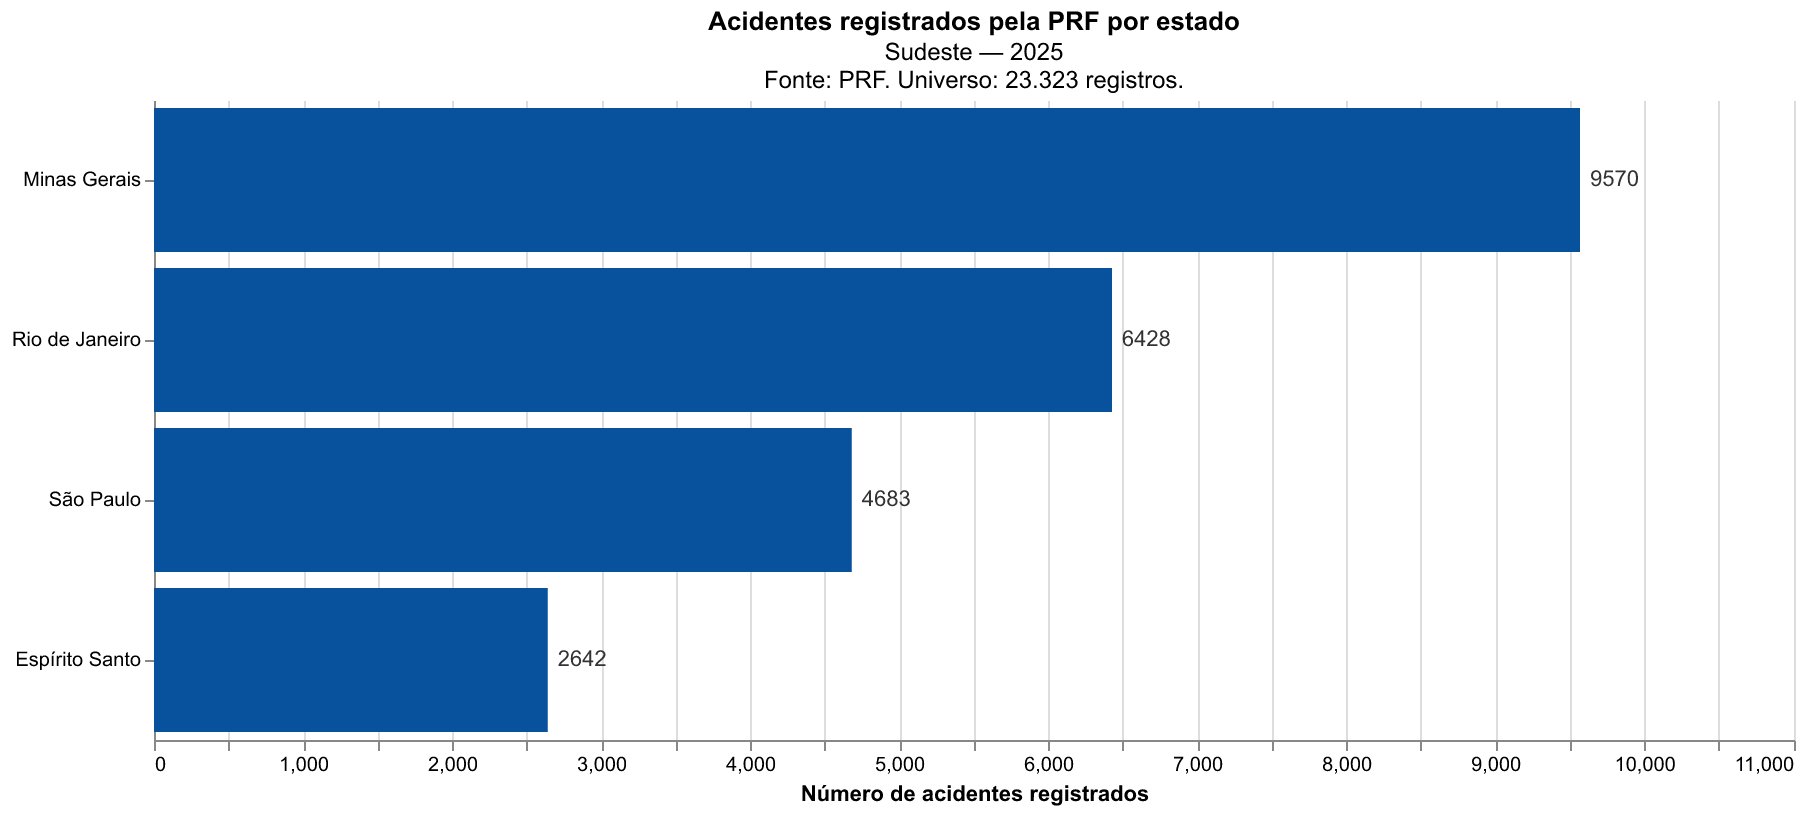

In [7]:
limite_x = float(resumo_uf["acidentes"].max()) * 1.15

base = alt.Chart(resumo_uf).encode(
    x=alt.X(
        "acidentes:Q",
        title="Número de acidentes registrados",
        scale=alt.Scale(domain=[0, limite_x])
    ),
    y=alt.Y(
        "estado:N",
        title=None,
        sort="-x"
    )
)

barras = base.mark_bar(
    color="#08519c"
).encode(
    tooltip=[
        alt.Tooltip(
            "estado:N",
            title="Estado"
        ),
        alt.Tooltip(
            "acidentes:Q",
            title="Acidentes",
            format="d"
        ),
        alt.Tooltip(
            "percentual_total_regional:Q",
            title="Participação regional (%)",
            format=".2f"
        )
    ]
)

rotulos = base.mark_text(
    align="left",
    baseline="middle",
    dx=5,
    color="#333333"
).encode(
    text=alt.Text(
        "acidentes:Q",
        format="d"
    )
)

grafico_uf = (
    barras + rotulos
).properties(
    width=820,
    height=320,
    title=alt.TitleParams(
        text="Acidentes registrados pela PRF por estado",
        subtitle=[
            "Sudeste — 2025",
            "Fonte: PRF. Universo: 23.323 registros."
        ]
    )
).configure_view(
    stroke=None
)

with alt.renderers.enable("png", scale_factor=2):
    display(grafico_uf)

Minas Gerais reúne a maior quantidade de acidentes registrados no recorte, com 9.570 ocorrências, correspondentes a 41,03% do total regional. Em seguida aparecem Rio de Janeiro, com 6.428 registros (27,56%); São Paulo, com 4.683 (20,08%); e Espírito Santo, com 2.642 (11,33%). Esses valores descrevem a distribuição dos registros da PRF entre os estados.

## Tratamento de dados.

observamos que criar uma camada do mapa contendo as rodovias federais da região ao invés de só plotar os acidentes seria uma abordagem melhor. Enquanto estávamos analisando percebemos que as rodovias federais ficam em poucas regiões do sudeste, e deixar essa representação sem identificar as rodovias iria dificultar imensamente a interpretação do leitor acerca da intensidade dos acidentes em cada região. Por isso, utilizamos o ArcGIS, um sistema de informações geográficas, para coletar os dados das rodovias federais e colocar como uma malha no nosso mapa (esses dados foram feitos no início de 2025, então bate de encontro com o dataset que estamos trabalhando). Ao lidar com os dados do ArcGIS, inicialmente excluímos as rodovias que foram planejadas e iremos analisar também as rovodias em obra de implantação, pois, ao pesquisar a terminologia, essas rodovias podem estar sob um leito natural. Então para saber se ela é ou não passível de análise no nosso dataset iremos comparar ao plotá-los. 

OBSERVAÇÃO: Percebemos que havia apenas uma rodovia em estado de obra de implantação, portanto optamos por deixá-la inclusa na construção da camada das rodovias.

A malha delimita a rede considerada no cálculo. O mapa de fundo do OpenStreetMap oferece referências geográficas, enquanto os limites estaduais obtidos do IBGE permitem distinguir os territórios dos quatro estados.

Organizamos a malha por UF e BR, reunimos as linhas conectadas quando possível e dividimos cada linha resultante em segmentos de até 10 km. O segmento final de uma linha pode ser menor. Sua origem depende da geometria da linha e não corresponde necessariamente aos marcos quilométricos oficiais da rodovia.

Para cada acidente, procuramos a linha mais próxima com a mesma UF e o mesmo código de BR informado no registro. Aceitamos a associação quando a distância até essa linha era de até 200 metros e não havia empate de menor distância detectado pelo procedimento. Em seguida, usamos a posição projetada ao longo da linha para determinar o segmento correspondente.

O limite de 200 metros foi uma escolha exploratória do grupo, sem validação externa de precisão. Para cada segmento, contamos os acidentes associados e dividimos essa quantidade por sua extensão em quilômetros. Assim, o indicador representado pelas cores é o número de acidentes associados por quilômetro, calculado em segmentos de até 10 km.

In [8]:
dados_mapa = sudeste.copy()

acidentes_geo = geo.GeoDataFrame(
    dados_mapa,
    geometry=geo.points_from_xy(
        dados_mapa["longitude"],
        dados_mapa["latitude"]
    ),
    crs="EPSG:4674"
)

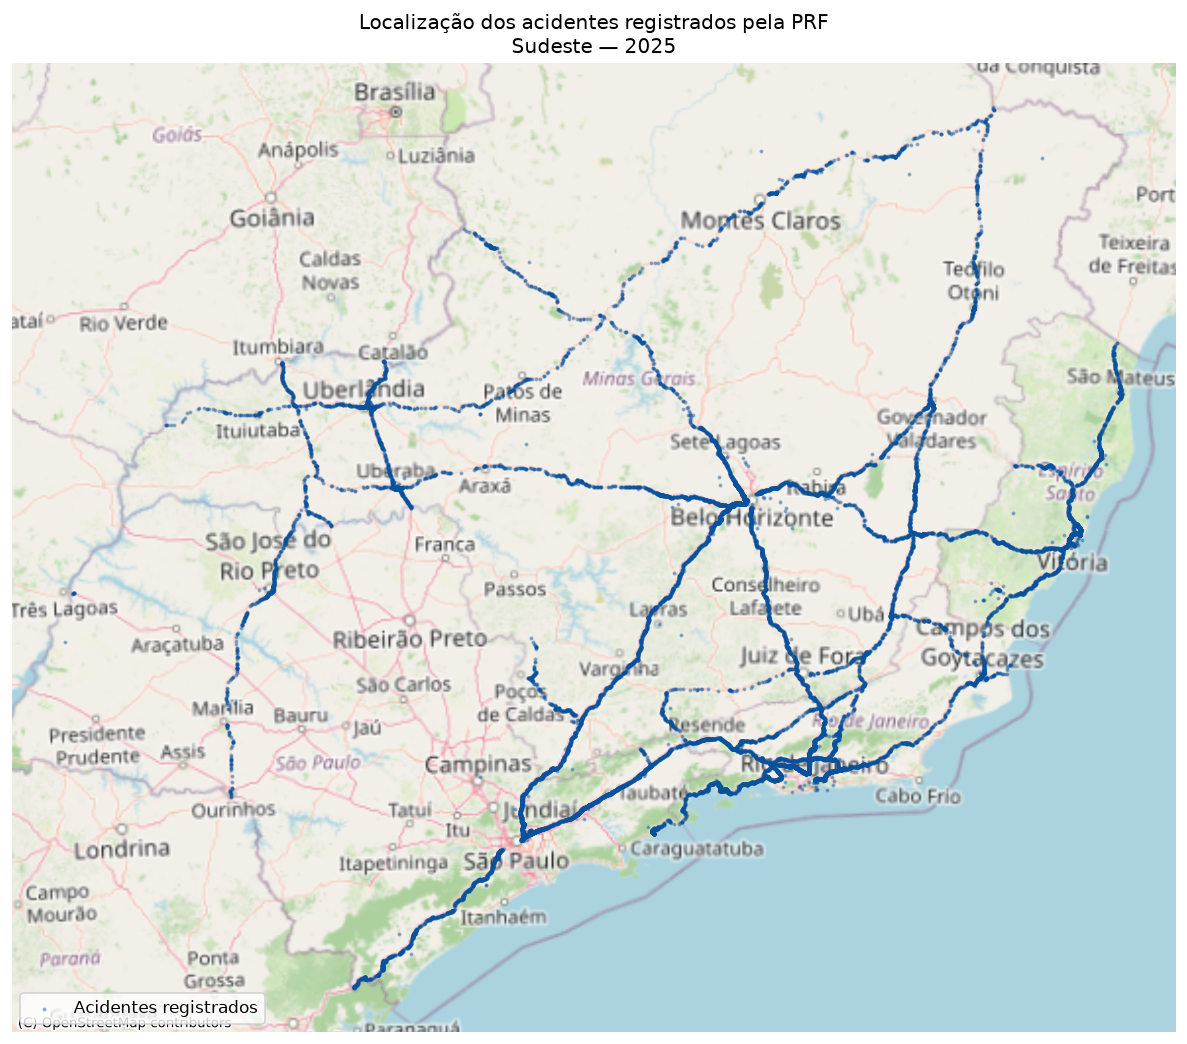

In [9]:
acidentes_figura = acidentes_geo.to_crs("EPSG:31983")

fig, ax = plt.subplots(figsize=(10, 9), dpi=120)

acidentes_figura.plot(
    ax=ax,
    color="#08519c",
    markersize=2,
    alpha=0.35,
    zorder=2,
    label="Acidentes registrados"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=acidentes_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Localização dos acidentes registrados pela PRF\n"
    "Sudeste — 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

Nesse gráfico conseguimos observar os acidentes a partir do mapa, ele nos mostra que é limitado tirar conclusões sem termos ciência da localização de todas as rodovias federais.

In [10]:
import requests

consulta = (
    "https://geo.infrasa.gov.br/server/rest/services/"
    "Hosted/Rodovias_Federais/FeatureServer/0/query"
)

parametros = {
    "where": "sg_uf IN ('MG', 'ES', 'RJ', 'SP')",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": 4326,
    "resultRecordCount": 20000,
    "f": "geojson"
}

resposta = requests.get(
    consulta,
    params=parametros,
    timeout=60
)

resposta.raise_for_status()
conteudo = resposta.json()

if "error" in conteudo:
    raise RuntimeError(conteudo["error"])

malha = geo.GeoDataFrame.from_features(
    conteudo["features"],
    crs="EPSG:4326"
)

In [11]:
malha_analise = malha[
    (malha["ds_jurisdi"] == "Federal")
    & ~malha["ds_legenda"].isin([
        "Planejada"
    ])
].copy()

In [12]:
malha_analise = malha_analise.rename(columns={
    "fid": "id_trecho",
    "sg_uf": "uf",
    "vl_br": "br",
    "vl_km_inic": "km_inicial",
    "vl_km_fina": "km_final",
    "vl_extensa": "extensao_km"
})

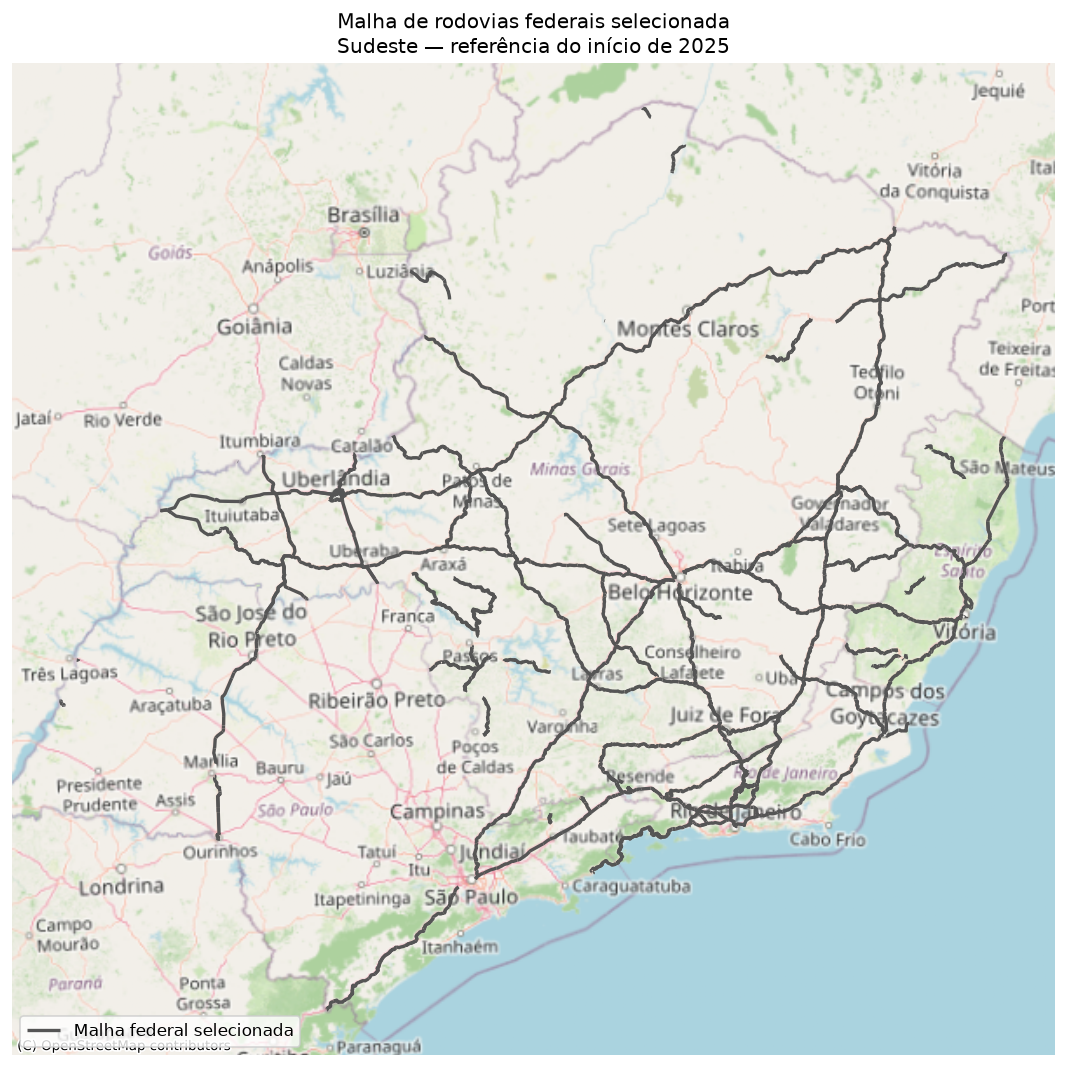

In [13]:
malha_figura = malha_analise.to_crs("EPSG:31983")

fig, ax = plt.subplots(figsize=(10, 9), dpi=120)

malha_figura.plot(
    ax=ax,
    color="#555555",
    linewidth=2,
    zorder=2,
    label="Malha federal selecionada"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=malha_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Malha de rodovias federais selecionada\n"
    "Sudeste — referência do início de 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

Aqui conseguimos observar todas as rodovias federais do sudeste no ano de 2025, e com isso temos certeza de que os acidentes contidos nos nossos dados não estão distribuídos em todas as rodovias, o que deixa explícito a necessidade de comparar a concentração usando uma malha das rodovias para uma melhor interpretação.

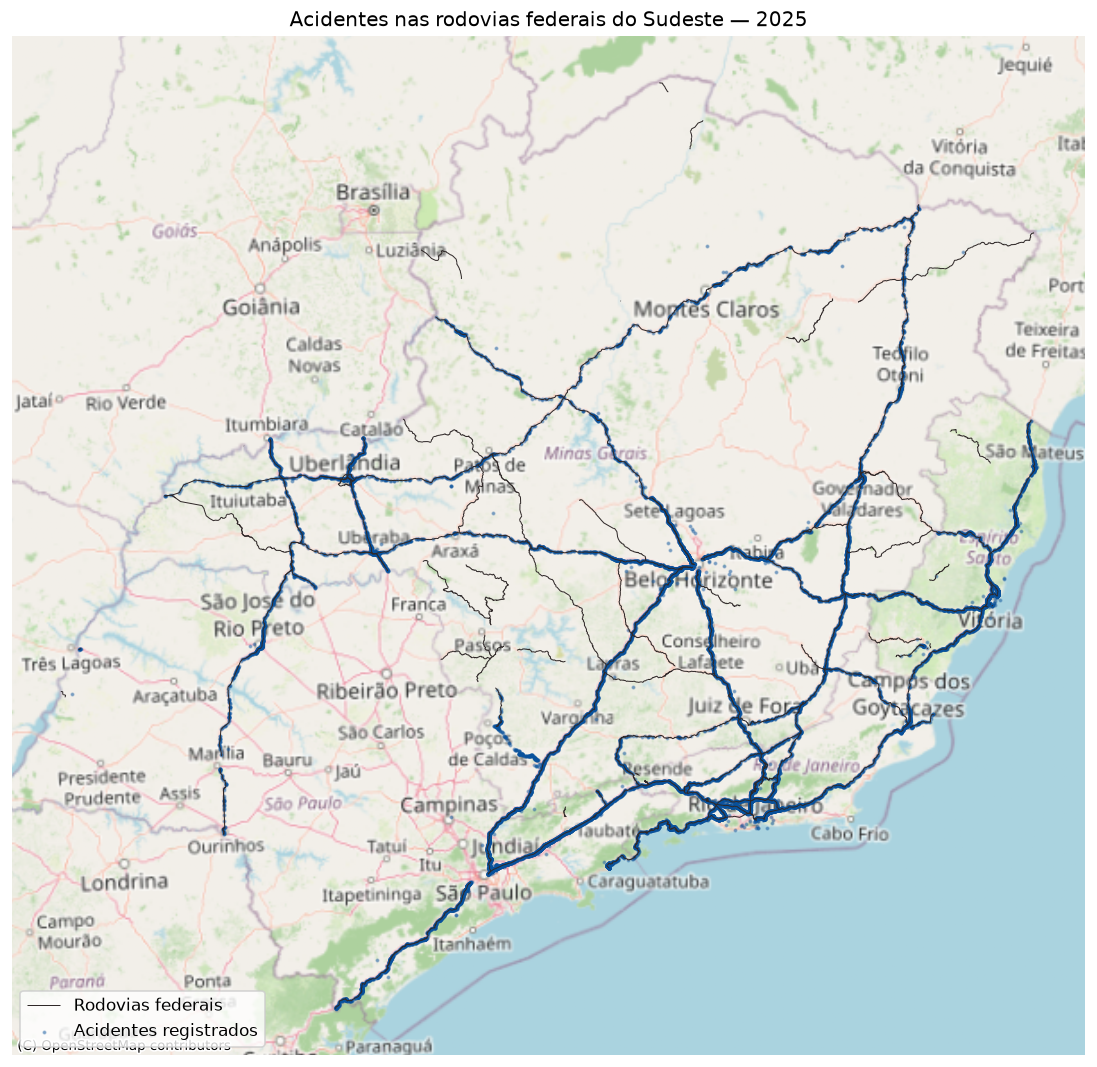

In [14]:
crs_figura = "EPSG:31983"

malha_figura = malha_analise.to_crs(crs_figura)
acidentes_figura = acidentes_geo.to_crs(crs_figura)

fig, ax = plt.subplots(
    figsize=(10, 9),
    dpi=120
)

malha_figura.plot(
    ax=ax,
    color="#2F2828",
    linewidth=0.6,
    label="Rodovias federais"
)

acidentes_figura.plot(
    ax=ax,
    color="#08519c",
    markersize=2,
    alpha=0.35,
    label="Acidentes registrados"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=malha_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Acidentes nas rodovias federais do Sudeste — 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

No mapa acima percebemos que existe alguns poucos casos em que os acidentes não estão acima de uma rodovia federal, mas a maioria esmagadora está de acordo com o mapa das rodovias que fizemos. A partir de agora, para fazermos nosso geográfico evidenciando a distribuição de acidentes na região sudeste, iremos fazer com que cada acidente esteja designado a uma parte da rodovia, para que dessa forma possamos calcular a concentração de acidentes em uma determinada distância por rodovia (iremos usar 10km como base).

In [15]:
malha_base = malha_analise[
    ["uf", "br", "geometry"]
].copy()

acidentes_base = acidentes_geo[
    ["id", "uf", "br", "km", "municipio", "geometry"]
].copy()

for tabela in [malha_base, acidentes_base]:
    tabela["br"] = (
        tabela["br"]
        .astype(int)
        .astype(str)
        .str.zfill(3)
    )

#Pegamos apenas as colunas necessária e padronizamos os números da BR das tabelas.

In [16]:
redes = {}
partes_mapa = []

for (uf, br), grupo in malha_base.groupby(["uf", "br"]):

    crs_metrico = grupo.estimate_utm_crs(
        datum_name="SIRGAS 2000"
    )

    rede = (
        grupo.to_crs(crs_metrico)
        .dissolve(by=["uf", "br"])
        .reset_index()
    )

    rede["geometry"] = rede.geometry.apply(line_merge)

    linhas = (
        rede.explode(index_parts=False)
        .reset_index(drop=True)
    )

    linhas["id_linha"] = [
        f"{uf}_{br}_{numero}"
        for numero in linhas.index
    ]

    redes[(uf, br)] = (crs_metrico, linhas)

    segmentos = []

    for linha in linhas.itertuples():

        comprimento = linha.geometry.length
        quantidade = ceil(comprimento / 10000)

        for numero in range(quantidade):

            inicio = numero * 10000
            fim = min(inicio + 10000, comprimento)

            pedaco = substring(
                linha.geometry,
                inicio,
                fim
            )

            segmentos.append({
                "id_segmento": f"{linha.id_linha}_{numero}",
                "uf": uf,
                "br": br,
                "extensao_km": pedaco.length / 1000,
                "geometry": pedaco
            })

    partes_geo = geo.GeoDataFrame(
        segmentos,
        geometry="geometry",
        crs=crs_metrico
    )

    # Simplifica somente as linhas usadas no desenho do mapa.
    partes_geo["geometry"] = partes_geo.geometry.simplify(10)

    partes_mapa.append(
        partes_geo.to_crs("EPSG:4326")
    )

segmentos_10km = geo.GeoDataFrame(
    pd.concat(partes_mapa, ignore_index=True),
    geometry="geometry",
    crs="EPSG:4326"
)

segmentos_10km.head()

,id_segmento,uf,br,extensao_km,geometry
0,ES_101_0_0,ES,101,10.0,"LINESTRING (-40.337 -20.218, -40.34713 -20.218..."
1,ES_101_0_1,ES,101,10.0,"LINESTRING (-40.3927 -20.2781, -40.39323 -20.2..."
2,ES_101_0_2,ES,101,10.0,"LINESTRING (-40.42019 -20.35787, -40.42142 -20..."
3,ES_101_0_3,ES,101,10.0,"LINESTRING (-40.45978 -20.41441, -40.45993 -20..."
4,ES_101_0_4,ES,101,10.0,"LINESTRING (-40.47535 -20.50074, -40.4748 -20...."


In [17]:
distancia_maxima = 200
resultados = []

for (uf, br), (crs_metrico, linhas) in redes.items():

    pontos = acidentes_base[
        (acidentes_base["uf"] == uf)
        & (acidentes_base["br"] == br)
    ].to_crs(crs_metrico)

    if pontos.empty:
        continue

    candidatos = geo.sjoin_nearest(
        pontos,
        linhas[["id_linha", "geometry"]],
        how="left",
        max_distance=distancia_maxima,
        distance_col="distancia_m"
    )

    multiplicidade = (
        candidatos.groupby("id")["id_linha"]
        .transform("size")
    )

    ids_ambiguos = candidatos.loc[
        multiplicidade > 1, "id"
    ].unique()

    for id_acidente in ids_ambiguos:
        resultados.append({
            "id": id_acidente,
            "id_segmento": None,
            "distancia_m": None,
            "status": "ambiguo"
        })

    linhas_por_id = linhas.set_index("id_linha").geometry

    for ponto in candidatos[
        multiplicidade == 1
    ].itertuples():

        id_segmento = None
        status = "distante"

        if pd.notna(ponto.id_linha):

            linha = linhas_por_id.loc[ponto.id_linha]

            posicao_m = linha.project(ponto.geometry)

            numero = min(
                int(posicao_m // 10000),
                ceil(linha.length / 10000) - 1
            )

            id_segmento = f"{ponto.id_linha}_{numero}"
            status = "associado"

        resultados.append({
            "id": ponto.id,
            "id_segmento": id_segmento,
            "distancia_m": ponto.distancia_m,
            "status": status
        })

associacoes = pd.DataFrame(resultados)

auditoria = acidentes_base.merge(
    associacoes,
    on="id",
    how="left",
    validate="one_to_one"
)

auditoria["status"] = auditoria["status"].fillna(
    "sem_malha_uf_br"
)

auditoria["status"].value_counts()

status
associado          22008
distante            1143
sem_malha_uf_br      172
Name: count, dtype: int64

Usando nossos métodos, conseguimos associar 22008 acidentes do total que temos. 

In [18]:
associados = auditoria[
    auditoria["status"] == "associado"
].copy()

contagens = (
    associados.groupby("id_segmento")["id"]
    .nunique()
)

segmentos_10km["acidentes"] = (
    segmentos_10km["id_segmento"]
    .map(contagens)
    .fillna(0)
    .astype(int)
)

segmentos_10km["acidentes_por_km"] = (
    segmentos_10km["acidentes"]
    / segmentos_10km["extensao_km"]
)

assert segmentos_10km["acidentes"].sum() == len(associados)

segmentos_10km[
    ["uf", "br", "extensao_km", "acidentes", "acidentes_por_km"]
].head()

,uf,br,extensao_km,acidentes,acidentes_por_km
0,ES,101,10.0,116,11.6
1,ES,101,10.0,204,20.4
2,ES,101,10.0,66,6.6
3,ES,101,10.0,21,2.1
4,ES,101,10.0,12,1.2


In [19]:
segmentos_10km.nlargest(
    10, "acidentes_por_km"
)[[
    "uf",
    "br",
    "extensao_km",
    "acidentes",
    "acidentes_por_km"
]]

,uf,br,extensao_km,acidentes,acidentes_por_km
1180,RJ,101,0.384861,17,44.171811
1403,SP,116,10.000000,378,37.800000
1178,RJ,101,0.140229,5,35.656043
1402,SP,116,10.000000,314,31.400000
1112,RJ,040,10.000000,271,27.100000
968,MG,381,10.000000,261,26.100000
1218,RJ,101,2.696478,65,24.105516
1111,RJ,040,10.000000,238,23.800000
1242,RJ,116,10.000000,235,23.500000
969,MG,381,3.295789,77,23.363144


In [20]:
url_estados = (
    "https://servicodados.ibge.gov.br/"
    "api/v3/malhas/regioes/SE"
)

resposta_estados = requests.get(
    url_estados,
    params={
        "formato": "application/vnd.geo+json",
        "intrarregiao": "UF",
        "qualidade": "minima"
    },
    timeout=60
)

resposta_estados.raise_for_status()

estados = geo.GeoDataFrame.from_features(
    resposta_estados.json()["features"],
    crs="EPSG:4326"
)

estados["uf"] = estados["codarea"].astype(str).map({
    "31": "MG",
    "32": "ES",
    "33": "RJ",
    "35": "SP"
})

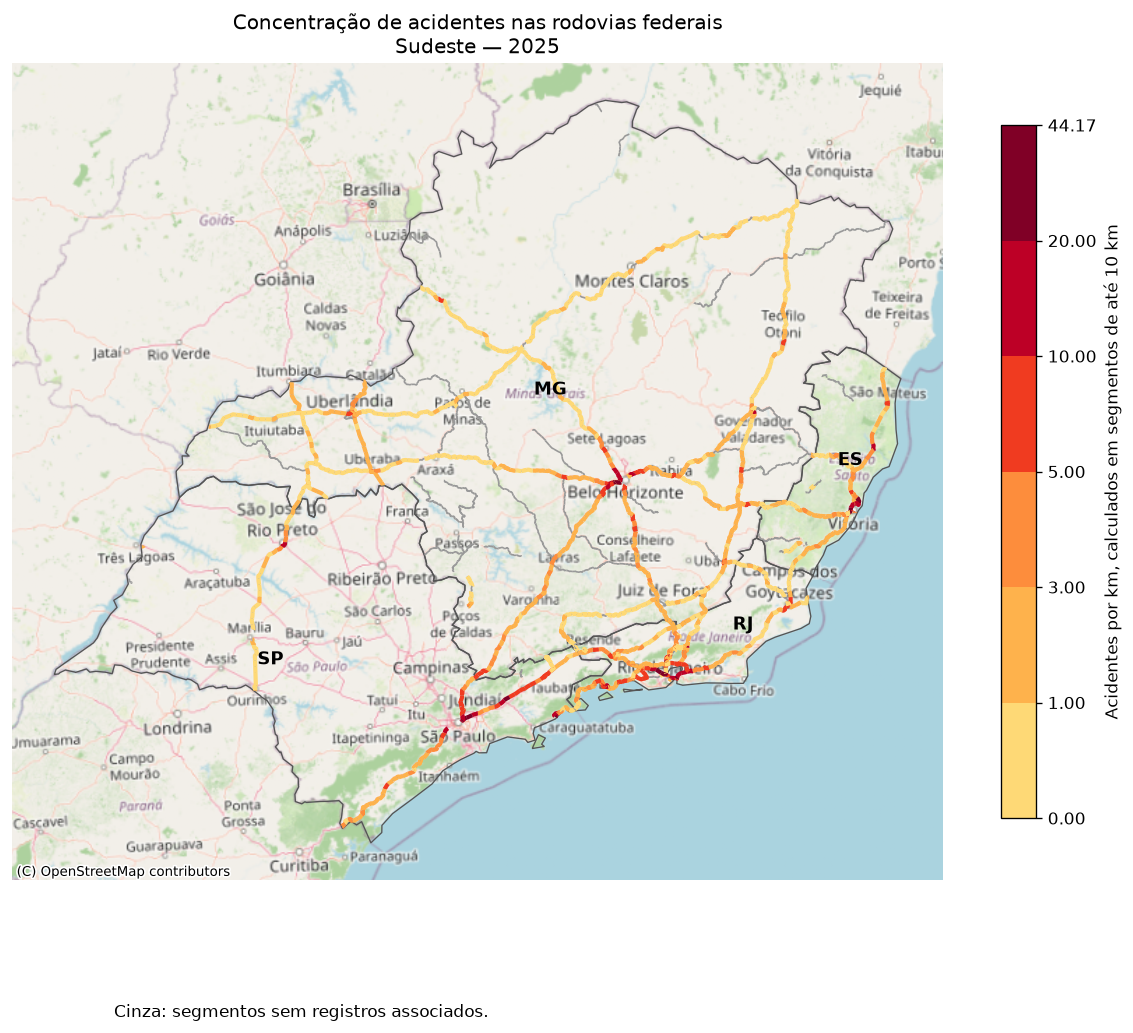

In [21]:
segmentos_figura = segmentos_10km.to_crs(crs_figura)
estados_figura = estados.to_crs(crs_figura)

fig, ax = plt.subplots(
    figsize=(10, 9),
    dpi=120
)

estados_figura.boundary.plot(
    ax=ax,
    color="#555555",
    linewidth=0.8,
    zorder=2
)

# Todos os segmentos aparecem inicialmente em cinza.
segmentos_figura.plot(
    ax=ax,
    color="#999999",
    linewidth=1
)

# Os segmentos com registros recebem as cores da concentração.
com_acidentes = segmentos_figura[
    segmentos_figura["acidentes"] > 0
]

maximo = max(
    20.1,
    float(com_acidentes["acidentes_por_km"].max())
)

limites = [0, 1, 3, 5, 10, 20, maximo]

cores = ListedColormap([
    "#fed976",
    "#feb24c",
    "#fd8d3c",
    "#f03b20",
    "#bd0026",
    "#800026"
])

normalizacao = BoundaryNorm(
    limites,
    ncolors=cores.N,
    clip=True
)
com_acidentes.plot(
    ax=ax,
    column="acidentes_por_km",
    cmap=cores,
    norm=normalizacao,
    linewidth=2.5,
    zorder=3,
    legend=True,
    legend_kwds={
        "label": "Acidentes por km, calculados em segmentos de até 10 km",
        "ticks": limites,
        "spacing": "uniform",
        "shrink": 0.7
    }
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=segmentos_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Concentração de acidentes nas rodovias federais\n"
    "Sudeste — 2025"
)

ax.set_axis_off()

fig.text(
    0.1, 0.02,
    "Cinza: segmentos sem registros associados."
)
for estado in estados_figura.itertuples():

    ponto_rotulo = estado.geometry.representative_point()

    ax.text(
        ponto_rotulo.x,
        ponto_rotulo.y,
        estado.uf,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        zorder=4
    )

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

## Conclusão:

Os acidentes registrados pela PRF no Sudeste em 2025 apresentam diferenças tanto nos totais por estado quanto na concentração local ao longo da malha. Minas Gerais reúne a maior parcela dos registros regionais com aproximadamente 41% dos registros de acidentes.

Ao analisar a concentração de acidentes nas rodovias federais do Sudeste, podemos perceber que existe uma quantidade considerável de segmentos sem registros associados. Mas de uma forma geral, os acidentes ficaram bem distribuídos nas rodovias. Entretanto, nas rodovias perto das capitais os acidentes aumentam grandemente. Além disso, na região litorânea de São Paulo e Rio de Janeiro as médias de acidentes são maiores que no restante dos estados.

# Quais meses, dias da semana e faixas horárias concentram mais ocorrências?